In [1]:
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
T = np.load("/home/intellimath/repos/bacteria-ID/data/wavenumbers.npy")
# X = np.load("/home/intellimath/repos/bacteria-ID/data/X_finetune.npy")
# X_test = np.load("/home/intellimath/repos/bacteria-ID/data/X_test.npy")
y = np.load("/home/intellimath/repos/bacteria-ID/data/y_finetune.npy")
y_test = np.load("/home/intellimath/repos/bacteria-ID/data/y_test.npy")

XX = np.load("/home/intellimath/repos/bacteria-ID/data/XX_finetune.npy")
XX_test = np.load("/home/intellimath/repos/bacteria-ID/data/XX_test.npy")
N, n = XX.shape 
print(XX.shape, y.shape, T.shape)

(3000, 1000) (3000,) (1000,)


In [5]:
# print(y)
def binarize(y):
    yb = np.zeros((len(y), 30))
    for k,yk in enumerate(y):
        yb[k,int(yk)] = 1.0
    return yb

yb = binarize(y)
yb_test = binarize(y_test)

In [6]:
import bacteria_id_config

In [7]:
import mlgrad.models as models
import mlgrad.regr as regr
import mlgrad.cls as cls
import mlgrad.pca as pca
import mlgrad.plots as plots
import mlgrad.funcs as funcs
import mlgrad.funcs2 as funcs2
import mlgrad.loss as loss
import mlgrad.gd as gd
import mlgrad.smooth as smooth
import mlgrad.inventory as inventory
from mlgrad.af import averaging_function
import mlgrad.avragg as avragg

import rampy
import pybaselines
import random

from irsa import io
from irsa.preprocess import despike, utils
import irsa.widgets as widgets
import irsa.spectra as spectra
import irsa.io as io

import scipy.special as special

from sklearn.preprocessing import scale
# import sklearn.metrics as metrics
from sklearn.metrics import accuracy_score, confusion_matrix

import copy

import ipywidgets
from IPython.display import display

import sys
print(sys.version)

# %matplotlib widget

3.13.12 (main, Feb  4 2026, 15:06:39) [GCC 15.2.0]


In [7]:
def plot_params(lfm):
    ax = plt.twinx(plt.gca())
    # ax.plot((0,0), (mod.n_param,0), ls='--', lw=0.5, color='b')
    for mod in lfm.models:
        param1 = np.asarray(mod.param[1:])
        # print(param1[0])
        param_p = param1.copy()
        param_m = param1.copy()
        param_p[param1 < 0] = 0
        param_m[param1 > 0] = 0
        ax.vlines(range(mod.n_input), 10*param_m, 10*param_p, color='k')
    ax.minorticks_on()

def argmax(X):
    return np.argmax(X, axis=1)
def npmax(X):
    return np.max(X, axis=1)

In [66]:
n_cls = 30
n_hidden = 60
nnmod = models.FFNetworkModel()
ll = models.LinearLayer(n, n_hidden)
# ll.use_regularizer(funcs2.AbsoluteNorm(), 200.0)
nnmod.add(ll)
nnmod.add(models.ScaleLayer(funcs.Sigmoidal(5.0), n_hidden))
ll2 = models.LinearLayer(n_hidden, n_cls)
# ll2.use_regularizer(funcs2.AbsoluteNorm(), 0.002)
nnmod.add(ll2)
nnmod.add(models.SoftMaxNormalizerLayer(n_cls, scale=5.0))

In [67]:
nnmod.allocate()
nnmod.init_param()
print('#params:', len(nnmod.param))

#params: 51580


In [68]:
alg = regr.regression(XX, yb, nnmod,
                 loss_func=loss.ErrorMultLoss2(funcs.SoftAbs_Sqrt(1.0)),
                 h=0.01, tol=1.0e-8, n_iter=100, init_param=False)

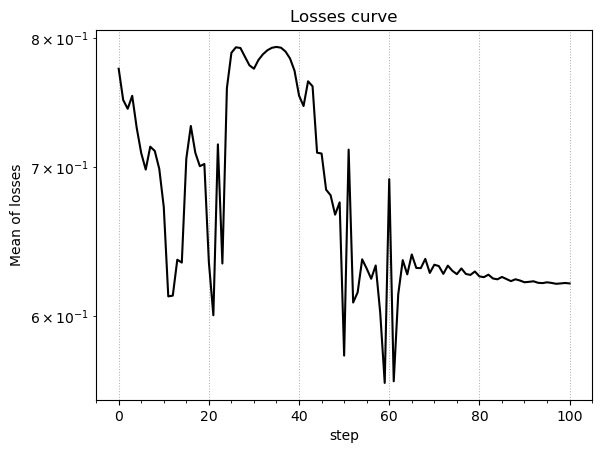

In [69]:
plots.plot_losses(alg, logscale=True)
plt.grid(lw=0.75, ls=':')
plt.minorticks_on()
plt.show()

In [70]:
y_p = np.argmax(nnmod.evaluate(XX), axis=1)
y_test_p = np.argmax(nnmod.evaluate(XX_test), axis=1)
print(y_p)
print(y_test_p)

[13 13 13 ... 13 13 13]
[13 13 13 ... 13 13 13]


In [71]:
print(accuracy_score(y, y_p))
print(accuracy_score(y_test, y_test_p))

0.033666666666666664
0.03333333333333333


In [72]:
print(np.max(nnmod.param))

0.6222676074766537


In [73]:
# plt.figure(figsize=(12,5))
# plots.plot_array2_vlines(np.array(ll.matrix))

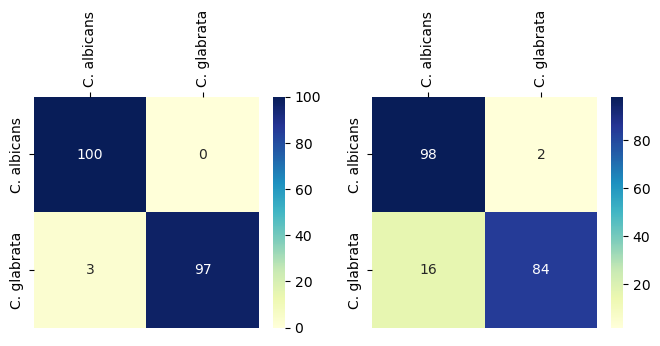

In [20]:
label=[key1, key2]
plt.figure(figsize=(8,3))
plt.subplot(1,2,1)
ax = sns.heatmap(cm, annot=True, cmap='YlGnBu', fmt='0.0f',
                 xticklabels=label, yticklabels=label)
ax.xaxis.tick_top()
plt.xticks(rotation=90) 
plt.subplot(1,2,2)
ax = sns.heatmap(cm_test, annot=True, cmap='YlGnBu', fmt='0.0f',
                 xticklabels=label, yticklabels=label)
ax.xaxis.tick_top()
plt.xticks(rotation=90) 
plt.show()

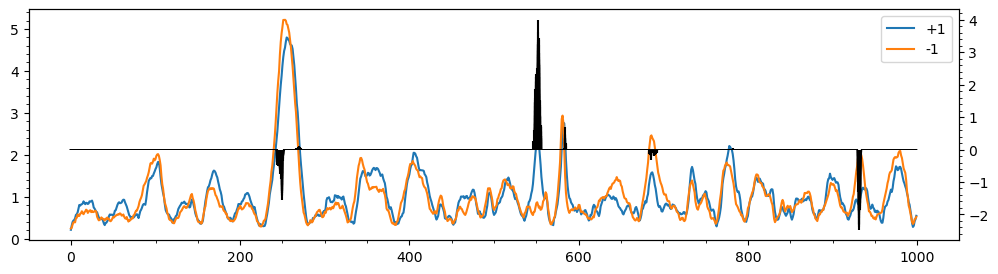

In [21]:
plt.figure(figsize=(12,3))
plt.plot(Y[Z==1].mean(axis=0), label="+1")
plt.plot(Y[Z==-1].mean(axis=0), label="-1")
plt.minorticks_on()
plt.legend()
plot_params(lfm)
plt.show()
# print(np.asarray(lfm1.models[0].param))